In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.metrics import accuracy_score
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.tree import DecisionTreeClassifier

# Carga del dataset
cancer = load_breast_cancer(as_frame=True)
df = cancer.frame

1. Gráfico de dispersión (Radio medio vs. Textura media)

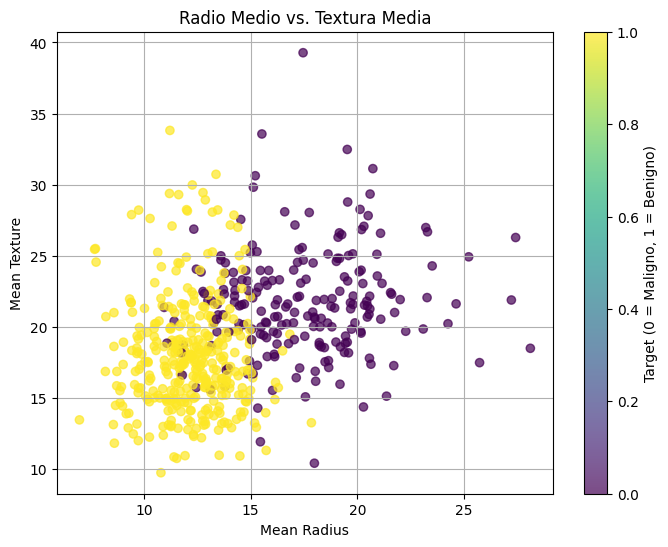

In [3]:
plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    df["mean radius"],
    df["mean texture"],
    c=df["target"],
    cmap="viridis",
    alpha=0.7,
)
plt.title("Radio Medio vs. Textura Media")
plt.xlabel("Mean Radius")
plt.ylabel("Mean Texture")
plt.colorbar(scatter, label="Target (0 = Maligno, 1 = Benigno)")
plt.grid(True)
plt.show()

**2. Conclusión visual de la separación de clases**

Los tumores malignos (clase 0) tienden a concentrarse en valores más altos de radio medio y textura media, mientras que los tumores benignos (clase 1) se ubican en valores significativamente menores de radio medio. Aunque existe cierta superposición en la zona media de la textura, el radio medio funciona como un separador muy claro entre ambas clases.

**3. Feature Engineering (shape_ratio)**

In [4]:
df["shape_ratio"] = df["mean area"] / df["mean perimeter"]

**4. Definición de variables X e y**

In [5]:
X = df.drop(columns=["target"])
y = df["target"]

**5. División Train/Test (80% train, 20% test)**

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

**6. Entrenamiento de DecisionTreeClassifier con max_depth=3**

In [7]:
clf = DecisionTreeClassifier(max_depth=3, random_state=42)
clf.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=3, random_state=42)

**7. Predicción y evaluación con accuracy_score**

In [8]:
y_pred = clf.predict(X_test)
acc_inicial = accuracy_score(y_test, y_pred)
print(f"Accuracy en el set de prueba (max_depth=3): {acc_inicial:.4f}")

Accuracy en el set de prueba (max_depth=3): 0.9561


**8. Bucle iterativo de profundidades (1 a 15)**

In [9]:
train_acc = []
test_acc = []
depths = range(1, 16)

for d in depths:
  model = DecisionTreeClassifier(max_depth=d, random_state=42)
  model.fit(X_train, y_train)

  # Cálculo de métricas
  train_acc.append(accuracy_score(y_train, model.predict(X_train)))
  test_acc.append(accuracy_score(y_test, model.predict(X_test)))

**9. Gráfico de Overfitting (Train vs. Test)**

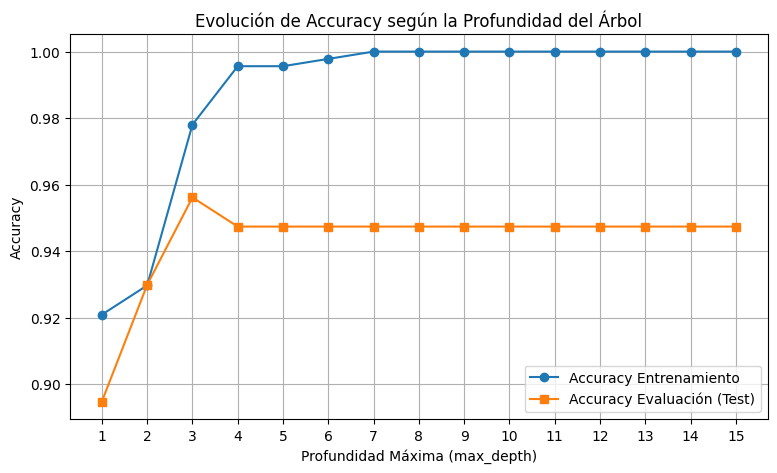

In [10]:
plt.figure(figsize=(9, 5))
plt.plot(depths, train_acc, label="Accuracy Entrenamiento", marker="o")
plt.plot(depths, test_acc, label="Accuracy Evaluación (Test)", marker="s")
plt.title("Evolución de Accuracy según la Profundidad del Árbol")
plt.xlabel("Profundidad Máxima (max_depth)")
plt.ylabel("Accuracy")
plt.xticks(list(depths))
plt.legend()
plt.grid(True)
plt.show()

En max_depth = 3, el modelo alcanza su máximo rendimiento en el conjunto de prueba (~95.6%). A partir de max_depth = 4, la precisión en el conjunto de entrenamiento continúa subiendo hasta llegar a 100% (profundidad 7), mientras que la precisión de prueba disminuye y se estanca en 94.7%. Esta divergencia evidencia que el modelo memoriza el conjunto de entrenamiento (overfitting) a mayores profundidades.

**10. Optimización de hiperparámetros con GridSearchCV**

In [11]:
param_grid = {"max_depth": range(1, 16)}
grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42), param_grid, cv=5
)
grid.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=DecisionTreeClassifier(random_state=42),
             param_grid={'max_depth': range(1, 16)})

**11. Resultados e impresión del mejor hiperparámetro**

In [12]:
print("Mejor hiperparámetro encontrado:", grid.best_params_)
print(
    f"Mejor accuracy promedio en validación cruzada: {grid.best_score_:.4f}"
)

Mejor hiperparámetro encontrado: {'max_depth': 3}
Mejor accuracy promedio en validación cruzada: 0.9297


GridSearchCV devuelve que el valor óptimo de profundidad es {'max_depth': 3}, lo cual coincide exactamente con la zona óptima identificada en la gráfica de Matplotlib antes de que comience el overfitting.  